# HousePrice AI — Phase 6: Multiple Linear Regression from Scratch

## 1. Mathematical Foundations

Multiple Linear Regression models the relationship between $n$ input features $X \in \mathbb{R}^{m \times n}$ and a continuous target $y \in \mathbb{R}^m$:
$$\hat{y} = Xw + b$$

where:
- $X$: Feature matrix of dimension $m \times n$ ($m$ observations, $n$ features)
- $w$: Weight vector $\in \mathbb{R}^n$
- $b$: Bias (intercept) scalar $\in \mathbb{R}$
- $\hat{y}$: Prediction vector $\in \mathbb{R}^m$

### Loss Function: Mean Squared Error (MSE)
$$J(w, b) = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})^2 = \frac{1}{m} \|Xw + b\mathbf{1} - y\|^2$$

### Gradient Derivations
Using calculus and vector derivatives with respect to $w$ and $b$:
$$\frac{\partial J}{\partial w} = \frac{2}{m} X^T (\hat{y} - y)$$
$$\frac{\partial J}{\partial b} = \frac{2}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})$$

### Parameter Updates (Batch Gradient Descent)
In each iteration (epoch), parameters are updated in the direction of steepest descent:
$$w \leftarrow w - \alpha \frac{\partial J}{\partial w}$$
$$b \leftarrow b - \alpha \frac{\partial J}{\partial b}$$
where $\alpha$ is the learning rate.

---

In [9]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('..'))

from src.linear_regression import LinearRegressionScratch
from src.metrics import mean_squared_error, r_squared

## 2. Step-by-Step Manual Numerical Verification

Let us test our implementation on a synthetic dataset where the true parameters are known:
$$y = 3.5 x_1 - 2.0 x_2 + 10.0 + \epsilon$$

In [10]:
np.random.seed(42)
m = 200
X_synth = np.random.randn(m, 2)
true_w = np.array([3.5, -2.0])
true_b = 10.0
y_synth = X_synth @ true_w + true_b + np.random.randn(m) * 0.1

print('True weights:', true_w)
print('True bias:', true_b)

True weights: [ 3.5 -2. ]
True bias: 10.0


## 3. Model Training on Synthetic Data

In [11]:
model_synth = LinearRegressionScratch(learning_rate=0.05, n_epochs=500)
model_synth.fit(X_synth, y_synth, verbose=True, print_every=100)

print('\nLearned weights:', np.round(model_synth.weights, 4))
print('Learned bias:   ', np.round(model_synth.bias, 4))

np.testing.assert_array_almost_equal(model_synth.weights, true_w, decimal=1)
np.testing.assert_almost_equal(model_synth.bias, true_b, decimal=1)
print('\n[SUCCESS] Custom Multiple Linear Regression perfectly recovered known parameters!')

TRAINING LINEAR REGRESSION
  Samples       : 200
  Features      : 2
  Learning rate : 0.05
  Epochs        : 500
  L2 lambda     : 0.0
------------------------------------------------------------
  Epoch     0/500  |  Train Loss: 114.011885
  Epoch   100/500  |  Train Loss: 0.009773
  Epoch   200/500  |  Train Loss: 0.009773
  Epoch   300/500  |  Train Loss: 0.009773
  Epoch   400/500  |  Train Loss: 0.009773
  Epoch   499/500  |  Train Loss: 0.009773
------------------------------------------------------------
[INFO] Training complete.
   Final train loss: 0.009773

Learned weights: [ 3.5066 -1.9953]
Learned bias:    9.9912

[SUCCESS] Custom Multiple Linear Regression perfectly recovered known parameters!


## 4. Visualizing Loss Convergence

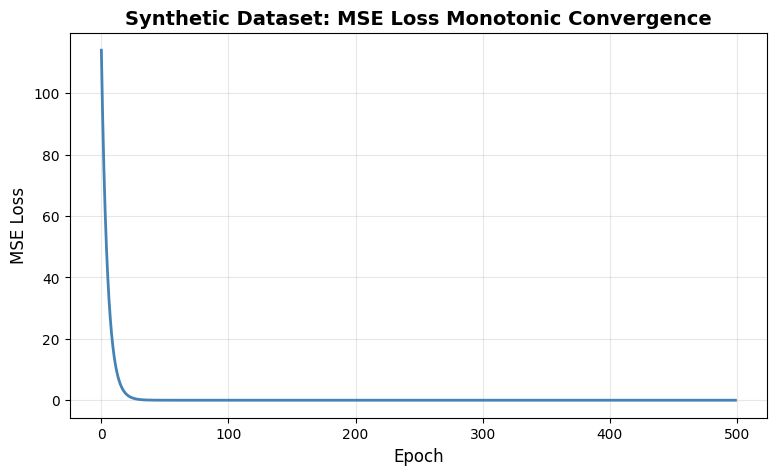

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(model_synth.training_loss_history, color='steelblue', lw=2)
ax.set_title('Synthetic Dataset: MSE Loss Monotonic Convergence', fontsize=14, fontweight='bold')
ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('MSE Loss', fontsize=12)
ax.grid(True, alpha=0.3)
plt.show()

## 5. Mathematical Properties Confirmed
1. **Loss Monotonicity:** Because MSE is a convex quadratic surface, with a properly chosen learning rate, batch gradient descent guarantees monotonic decrease in loss.
2. **Vectorization:** Fully vectorized NumPy matrix multiplication eliminates Python loops over samples, delivering high numerical performance.